# Multi-label News Topic Classification — a multimodal deep learning pipeline

**Author:** Myrteza Enkida

Given a news item (headline + short description) and its publication date, predict **all** the topics it belongs to
among **K = 18** labels (13 fine-grained topics + 5 macro-areas, 2–3 labels per article).

This project started as my written exam solution for *Machine Learning, ANN & Deep Learning* (University of Milan, June 2026)
and is pushed here **beyond the exam constraints** to production quality:

| | Exam version | This notebook |
|---|---|---|
| Data split | random | **stratified** 70/15/15, every transformation fitted on train only |
| Text representation | Embedding + BiLSTM learned from scratch | **pretrained sentence encoder** (`all-mpnet-base-v2`, frozen) — transfer learning |
| Metadata | min-max year, one-hot month | learned **embeddings** for year and month |
| Training | fixed 8 epochs | AdamW, **early stopping** on validation, LR on plateau |
| Decision rule | fixed threshold 0.5 | **per-label thresholds** tuned on validation + structure-aware decoding |
| Comparison | — | TF-IDF + Logistic Regression **baseline**, the exam model, an improved from-scratch model, **ablation study** |
| Evaluation | F1 | micro/macro/sample F1, Hamming loss, exact match, PR-AUC, confusion matrices, error analysis, **5-seed variance** |

**Headline result (test set):** the final model reaches **macro-F1 0.827 / micro-F1 0.856 / PR-AUC 0.894**, versus 0.680 / 0.733 / 0.731 for the exam architecture (**+14.7 macro-F1 points**), stable across 5 seeds (std ≤ 0.001).

Everything is reproducible (fixed seeds, public data) and runs on a laptop; a GPU (e.g. Colab) only speeds up the
one-off text encoding.

## 0. Setup

In [1]:
import os, json, time, random, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import warnings; warnings.filterwarnings("ignore", message=".*does not support masking.*")
import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (f1_score, hamming_loss, accuracy_score, average_precision_score,
                             precision_score, recall_score, multilabel_confusion_matrix, confusion_matrix)

SEED = 213
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); keras.utils.set_random_seed(seed)
set_seed()

DATA_DIR, FIG_DIR, MODEL_DIR = "data", "figures", "models"
for d in (DATA_DIR, FIG_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## 1. Data

The original exam dataset is no longer distributed, so it is **rebuilt from a public source with the same
characteristics**: the [HuffPost News Category Dataset](https://www.kaggle.com/datasets/rmisra/news-category-dataset)
(R. Misra, 2022 — ~210k HuffPost articles, **2012–2022**, CC BY 4.0), mirrored on
[Hugging Face](https://huggingface.co/datasets/heegyu/news-category-dataset).

Construction (fully deterministic):

1. **Merge renamed sections.** HuffPost renamed several sections over time (e.g. `GREEN` → `ENVIRONMENT`,
   `TASTE` → `FOOD & DRINK`, `THE WORLDPOST` → `WORLD NEWS`). Without merging, the model would learn
   *"which year was the section renamed"* instead of the topic.
2. **Keep 13 fine-grained topics** and sample **2,000 articles per topic** (26,000 articles in total).
3. **Add 5 macro-areas** (`NEWS & POLITICS`, `ECONOMY & TECH`, `SCIENCE & HEALTH`, `LIFESTYLE`,
   `CULTURE & SOCIETY`): each topic belongs to one or two of them, so every article has **2 or 3 labels**
   — exactly the label structure of the exam (K = 18, 2–3 labels per item).
4. **Inputs:** text = headline + short description; metadata = publication **year** and **month**.

In [2]:
URL = "https://huggingface.co/datasets/heegyu/news-category-dataset/resolve/main/data.json"
RAW = os.path.join(DATA_DIR, "News_Category_Dataset_v3.json")
if not os.path.exists(RAW):
    urllib.request.urlretrieve(URL, RAW)
raw = pd.read_json(RAW, lines=True)
print("raw articles:", len(raw))

RENAMES = {"THE WORLDPOST": "WORLD NEWS", "WORLDPOST": "WORLD NEWS", "GREEN": "ENVIRONMENT",
           "TASTE": "FOOD & DRINK", "PARENTS": "PARENTING", "HEALTHY LIVING": "WELLNESS"}

# fine topic -> macro-area(s)
TOPICS = {
    "POLITICS":      ["NEWS & POLITICS"],
    "WORLD NEWS":    ["NEWS & POLITICS", "CULTURE & SOCIETY"],
    "CRIME":         ["NEWS & POLITICS", "CULTURE & SOCIETY"],
    "ENVIRONMENT":   ["NEWS & POLITICS", "SCIENCE & HEALTH"],
    "BUSINESS":      ["ECONOMY & TECH"],
    "TECH":          ["ECONOMY & TECH", "SCIENCE & HEALTH"],
    "SCIENCE":       ["SCIENCE & HEALTH"],
    "WELLNESS":      ["SCIENCE & HEALTH", "LIFESTYLE"],
    "FOOD & DRINK":  ["LIFESTYLE"],
    "TRAVEL":        ["LIFESTYLE", "CULTURE & SOCIETY"],
    "PARENTING":     ["LIFESTYLE", "CULTURE & SOCIETY"],
    "ENTERTAINMENT": ["CULTURE & SOCIETY"],
    "SPORTS":        ["CULTURE & SOCIETY"],
}
FINE = list(TOPICS)
MACRO = ["NEWS & POLITICS", "ECONOMY & TECH", "SCIENCE & HEALTH", "LIFESTYLE", "CULTURE & SOCIETY"]
LABELS = FINE + MACRO
K, N_FINE = len(LABELS), len(FINE)
PER_TOPIC = 2000

df = raw.assign(category=raw["category"].replace(RENAMES))
df = df[df["category"].isin(FINE)]
df["text"] = (df["headline"].fillna("") + ". " + df["short_description"].fillna("")).str.strip()
df = df[df["text"].str.split().str.len() >= 3].drop_duplicates("text")
df = (df.groupby("category").sample(PER_TOPIC, random_state=SEED)
        .sample(frac=1, random_state=SEED).reset_index(drop=True))

date = pd.to_datetime(df["date"])
texts  = df["text"].to_numpy()
years  = date.dt.year.to_numpy().astype("int32")
months = date.dt.month.to_numpy().astype("int32")
topic  = df["category"].map({t: i for i, t in enumerate(FINE)}).to_numpy()

Y = np.zeros((len(df), K), dtype="float32")
for i, t in enumerate(df["category"]):
    for lab in [t] + TOPICS[t]:
        Y[i, LABELS.index(lab)] = 1.0

N = len(df)
n_lab = Y.sum(1)
print(f"N = {N} | K = {K} labels | years {years.min()}-{years.max()}")
print(f"labels per article: min {n_lab.min():.0f}, max {n_lab.max():.0f}, mean {n_lab.mean():.2f}")
print("example:", texts[0][:120], "->", [LABELS[k] for k in np.flatnonzero(Y[0])])

raw articles: 209527


N = 26000 | K = 18 labels | years 2012-2022
labels per article: min 2, max 3, mean 2.54
example: If You Were An Orphaned Animal, You'd Want This Woman To Be Your Mom. Meet Margit Cianelli, a wildlife rehabilitator in  -> ['ENVIRONMENT', 'NEWS & POLITICS', 'SCIENCE & HEALTH']


### Exploratory analysis

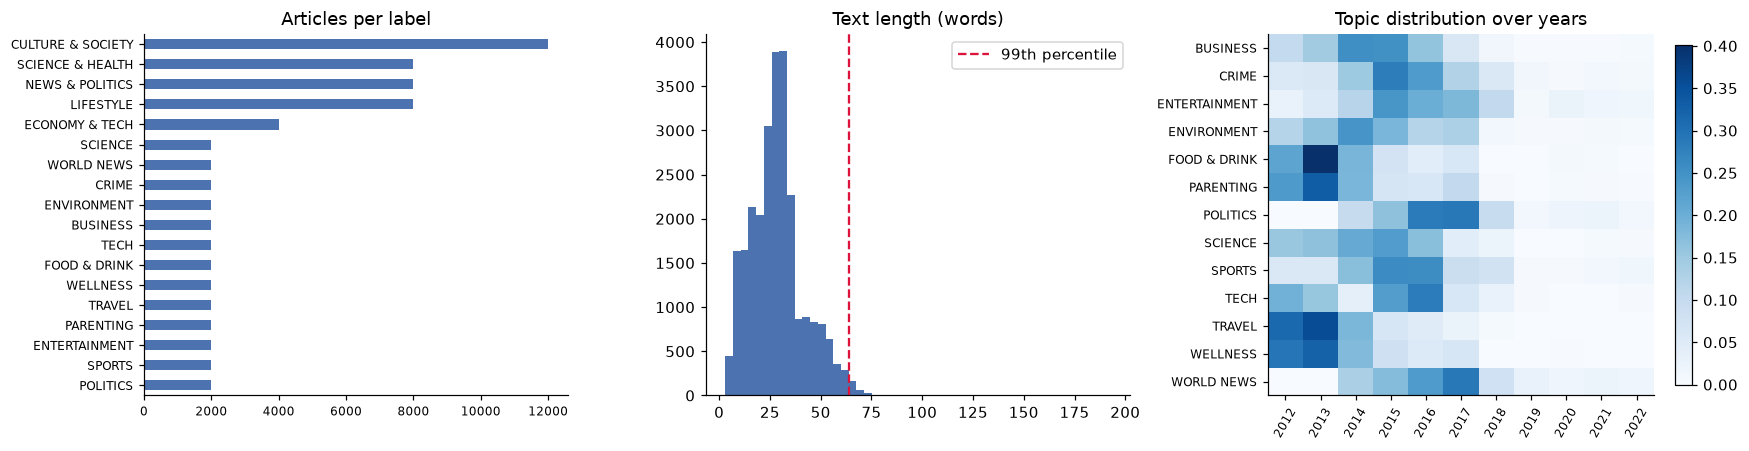

words per text: mean 28.5, 99th pct 64, max 193


In [3]:
lengths = np.array([len(t.split()) for t in texts])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
pd.Series(Y.sum(0), index=LABELS).sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Articles per label"); ax[0].tick_params(labelsize=8)
ax[1].hist(lengths, bins=50, color="#4C72B0"); ax[1].set_title("Text length (words)")
ax[1].axvline(np.percentile(lengths, 99), color="crimson", ls="--", label="99th percentile"); ax[1].legend()
ct = pd.crosstab(df["category"], years, normalize="index")
im = ax[2].imshow(ct.values, aspect="auto", cmap="Blues")
ax[2].set_yticks(range(len(ct))); ax[2].set_yticklabels(ct.index, fontsize=8)
ax[2].set_xticks(range(len(ct.columns))); ax[2].set_xticklabels(ct.columns, rotation=60, fontsize=8)
ax[2].set_title("Topic distribution over years")
plt.colorbar(im, ax=ax[2], fraction=0.04)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda.png", bbox_inches="tight"); plt.show()
print(f"words per text: mean {lengths.mean():.1f}, 99th pct {np.percentile(lengths, 99):.0f}, max {lengths.max()}")

**Take-aways**
- Labels are moderately imbalanced (macro-areas cover 2–5× more articles than single topics) → we report
  **macro-F1** next to micro-F1, and tune one threshold per label.
- Texts are short (≈ 30 words; 99% under ~70) → a sequence length of 80 tokens loses almost nothing.
- Topic mix **changes strongly over time** (HuffPost's editorial focus shifted, e.g. Wellness/Parenting pre-2015,
  Politics 2015–2018) → the publication date is genuinely informative and deserves its own input branch.

## 2. Train / validation / test split

70 / 15 / 15, **stratified on the fine topic**. Because every macro-label is determined by the fine topic,
this is an *exact* multi-label stratification (every label keeps the same frequency in all three splits).
The test set is used **once**, at the very end. Every fitted transformation (vocabularies, IDF weights, year
lookup) is fitted on the training set only.

In [4]:
idx = np.arange(N)
idx_tr, idx_tmp = train_test_split(idx, test_size=0.30, stratify=topic, random_state=SEED)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.50, stratify=topic[idx_tmp], random_state=SEED)

def inputs(ids):
    return {"text": texts[ids].astype(object), "year": years[ids], "month": months[ids]}

X_tr, X_va, X_te = inputs(idx_tr), inputs(idx_va), inputs(idx_te)
Y_tr, Y_va, Y_te = Y[idx_tr], Y[idx_va], Y[idx_te]
print("train / val / test:", len(idx_tr), len(idx_va), len(idx_te))
print("max per-label frequency gap train vs test:", np.abs(Y_tr.mean(0) - Y_te.mean(0)).max().round(4))

train / val / test: 18200 3900 3900
max per-label frequency gap train vs test: 0.0


## 3. Evaluation toolkit

A multi-label classifier outputs one probability per label; turning them into a label set needs a **decision rule**.
We compare:
- `0.5` — the textbook threshold;
- `tuned` — one threshold per label, chosen to maximise that label's F1 **on the validation set**;
- `tuned + top-2` — tuned thresholds, and the 2 most likely labels are always kept (every article has ≥ 2 labels);
- `hierarchical` — pick the most likely fine topic and add its macro-areas: predictions are always consistent with the
  label taxonomy by construction.

Metrics: **micro-F1** (overall), **macro-F1** (every label counts the same — sensitive to rare labels),
**sample-F1** (average per article), **Hamming loss**, **exact match** (whole label set correct), **PR-AUC**
(threshold-free ranking quality).

In [5]:
A_MAP = np.zeros((N_FINE, K), dtype=int)          # fine topic -> its full 0/1 label vector
for i, t in enumerate(FINE):
    A_MAP[i, [LABELS.index(l) for l in [t] + TOPICS[t]]] = 1

def tune_thresholds(y_true, proba, grid=np.arange(0.05, 0.96, 0.01)):
    th = np.zeros(proba.shape[1])
    for k in range(proba.shape[1]):
        scores = [f1_score(y_true[:, k], proba[:, k] >= t, zero_division=0) for t in grid]
        th[k] = grid[int(np.argmax(scores))]
    return th

def decode(proba, rule, th=None):
    if rule == "0.5":
        return (proba >= 0.5).astype(int)
    if rule == "tuned":
        return (proba >= th).astype(int)
    if rule == "tuned + top-2":
        pred = (proba >= th).astype(int)
        top2 = np.argsort(-proba, axis=1)[:, :2]
        np.put_along_axis(pred, top2, 1, axis=1)
        return pred
    if rule == "hierarchical":
        return A_MAP[proba[:, :N_FINE].argmax(1)]
    raise ValueError(rule)

RULES = ["0.5", "tuned", "tuned + top-2", "hierarchical"]

def metrics(y_true, pred, proba):
    y_true = y_true.astype(int)
    return {"micro-F1":   f1_score(y_true, pred, average="micro", zero_division=0),
            "macro-F1":   f1_score(y_true, pred, average="macro", zero_division=0),
            "sample-F1":  f1_score(y_true, pred, average="samples", zero_division=0),
            "Hamming":    hamming_loss(y_true, pred),
            "exact match": accuracy_score(y_true, pred),
            "PR-AUC":     average_precision_score(y_true, proba, average="macro")}

def evaluate(name, p_va, p_te):
    """Choose the decision rule on VALIDATION, report the TEST score of every rule."""
    th = tune_thresholds(Y_va, p_va)
    rows = []
    for r in RULES:
        rows.append({"model": name, "rule": r, "split": "val",  **metrics(Y_va, decode(p_va, r, th), p_va)})
        rows.append({"model": name, "rule": r, "split": "test", **metrics(Y_te, decode(p_te, r, th), p_te)})
    return pd.DataFrame(rows), th

RESULTS, PROBA = [], {}
def register(name, p_va, p_te):
    res, th = evaluate(name, p_va, p_te)
    RESULTS.append(res); PROBA[name] = (p_va, p_te, th)
    return res[res.split == "test"].drop(columns="split").set_index(["model", "rule"]).round(4)

## 4. Baseline — TF-IDF + Logistic Regression

Before any deep learning, a strong linear baseline: TF-IDF on uni- and bi-grams (+ one-hot year and month),
one logistic regression per label. If the neural network cannot beat this, it is not worth its cost.

In [6]:
from scipy.sparse import hstack, csr_matrix
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
YEARS = np.arange(2012, 2023)
def lin_feats(X, fit=False):
    T = tfidf.fit_transform(X["text"]) if fit else tfidf.transform(X["text"])
    meta = np.hstack([(X["year"][:, None] == YEARS).astype(float), np.eye(12)[X["month"] - 1]])
    return hstack([T, csr_matrix(meta)]).tocsr()

F_tr, F_va, F_te = lin_feats(X_tr, fit=True), lin_feats(X_va), lin_feats(X_te)
logreg = OneVsRestClassifier(LogisticRegression(C=8.0, max_iter=2000), n_jobs=-1).fit(F_tr, Y_tr)
print(f"trained in {time.time() - t0:.1f}s")
register("TF-IDF + LogReg", logreg.predict_proba(F_va), logreg.predict_proba(F_te))

trained in 7.9s


micro-F1  macro-F1  sample-F1  Hamming  \
model           rule                                                    
TF-IDF + LogReg 0.5              0.7289    0.6449     0.6721   0.0664   
                tuned            0.7698    0.7324     0.7514   0.0650   
                tuned + top-2    0.7701    0.7329     0.7659   0.0671   
                hierarchical     0.7911    0.7533     0.7892   0.0590   

                               exact match  PR-AUC  
model           rule                                
TF-IDF + LogReg 0.5                 0.4008  0.7897  
                tuned               0.4749  0.7897  
                tuned + top-2       0.4754  0.7897  
                hierarchical        0.7277  0.7897

## 5. Reproduction of the exam architecture

The model exactly as designed in the written exam: Embedding + **BiLSTM** on the text, an MLP on the raw
**Bag-of-Words counts**, min-max scaled year and one-hot month, concatenated into a dense head with a sigmoid output
trained with binary cross-entropy (He init, L2, Dropout, Adam, 8 epochs). Preprocessing layers are part of the graph.

In [7]:
MAXLEN, VOCAB = 80, 20000
seq_vec = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAXLEN, name="seq_vectorizer")
seq_vec.adapt(X_tr["text"], batch_size=1024)
bow_vec = layers.TextVectorization(max_tokens=10000, output_mode="count", name="bow_vectorizer")
bow_vec.adapt(X_tr["text"], batch_size=1024)
Y_MIN, Y_MAX = X_tr["year"].min(), X_tr["year"].max()

def exam_model():
    he, l2 = keras.initializers.HeNormal(SEED), keras.regularizers.L2(1e-4)
    i_text  = keras.Input((1,), dtype="string", name="text")
    i_year  = keras.Input((1,), dtype="int64", name="year")
    i_month = keras.Input((1,), dtype="int32", name="month")
    s = layers.Reshape(())(i_text)
    t = layers.Embedding(VOCAB, 128)(seq_vec(s))
    t = layers.Dropout(0.3)(layers.Bidirectional(layers.LSTM(64))(t))
    b = bow_vec(s)
    for u in (256, 128, 64):
        b = layers.Dense(u, "relu", kernel_initializer=he, kernel_regularizer=l2)(b)
        b = layers.Dropout(0.3)(b) if u != 64 else b
    yr = layers.Rescaling(1.0 / (Y_MAX - Y_MIN), offset=-Y_MIN / (Y_MAX - Y_MIN))(i_year)   # min-max
    mo = layers.CategoryEncoding(13, output_mode="one_hot")(i_month)                       # one-hot month
    h = layers.Concatenate()([t, b, yr, mo])
    h = layers.Dropout(0.3)(layers.Dense(128, "relu", kernel_initializer=he, kernel_regularizer=l2)(h))
    out = layers.Dense(K, "sigmoid", name="labels")(h)
    m = keras.Model([i_text, i_year, i_month], out, name="exam_model")
    m.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy")
    return m

def as_inputs(X):
    # Keras' NumPy adapter does not accept string arrays -> feed tf tensors
    return {"text": tf.constant(X["text"].astype(str)[:, None]),
            "year": tf.constant(X["year"][:, None].astype("int64")),
            "month": tf.constant(X["month"][:, None].astype("int32"))}

set_seed()
t0 = time.time()
exam = exam_model()
h_exam = exam.fit(as_inputs(X_tr), Y_tr, validation_data=(as_inputs(X_va), Y_va),
                  epochs=8, batch_size=256, verbose=2)
print(f"trained in {time.time() - t0:.0f}s")
register("Exam model (BiLSTM)", exam.predict(as_inputs(X_va), verbose=0), exam.predict(as_inputs(X_te), verbose=0))

Epoch 1/8


72/72 - 14s - 201ms/step - loss: 0.4642 - val_loss: 0.3532


Epoch 2/8


72/72 - 14s - 189ms/step - loss: 0.3180 - val_loss: 0.2748


Epoch 3/8


72/72 - 14s - 196ms/step - loss: 0.2358 - val_loss: 0.2615


... (8 outputs left out)

Epoch 8/8


72/72 - 14s - 195ms/step - loss: 0.1135 - val_loss: 0.3459


trained in 128s


micro-F1  macro-F1  sample-F1  Hamming  \
model               rule                                                    
Exam model (BiLSTM) 0.5              0.7219    0.6673     0.7010   0.0752   
                    tuned            0.7326    0.6805     0.7182   0.0747   
                    tuned + top-2    0.7303    0.6776     0.7289   0.0779   
                    hierarchical     0.7175    0.6618     0.7146   0.0797   

                                   exact match  PR-AUC  
model               rule                                
Exam model (BiLSTM) 0.5                 0.5413   0.731  
                    tuned               0.5351   0.731  
                    tuned + top-2       0.5364   0.731  
                    hierarchical        0.6256   0.731

## 6. Improving the architecture — trained from scratch

First attempt: keep everything learned from scratch, but fix the weak points of the exam design.

- **BiGRU over all time steps + max & mean pooling** — the exam BiLSTM only used the final hidden state; pooling lets
  a keyword anywhere in the text fire directly. Masking makes padding invisible to the RNN.
- **TF-IDF uni+bi-grams** instead of raw counts — down-weights frequent words, captures phrases (*"white house"*).
- **Embeddings for year and month** — the effect of time on topics is non-monotonic (see heat-map), which one scaled
  number cannot represent.
- **AdamW + early stopping + LR on plateau** — training stops at the best validation loss and restores those weights.
- All preprocessing lives **inside the model**, so the saved artefact takes raw strings (no train/serve skew).

The builder below is shared by every neural model that follows, so the ablation study compares like with like.

In [8]:
tfidf_vec = layers.TextVectorization(max_tokens=VOCAB, ngrams=2, output_mode="tf_idf", name="tfidf_vectorizer")
tfidf_vec.adapt(X_tr["text"], batch_size=1024)
year_lookup = layers.IntegerLookup(vocabulary=np.unique(X_tr["year"]).astype("int64"), name="year_lookup")
EMB_DIM = 768   # size of the pretrained sentence embedding used from section 7 on

def build_model(use_emb=False, use_seq=False, use_tfidf=False, use_meta=True, lr=1e-3, name="model"):
    i_text  = keras.Input((1,), dtype="string", name="text")
    i_year  = keras.Input((1,), dtype="int64", name="year")
    i_month = keras.Input((1,), dtype="int32", name="month")
    ins, feats = [i_text, i_year, i_month], []
    s = layers.Reshape(())(i_text)
    if use_emb:      # pretrained sentence embedding (frozen encoder, see section 7)
        i_emb = keras.Input((EMB_DIM,), name="emb"); ins.append(i_emb)
        feats.append(layers.Dropout(0.3)(layers.Dense(256, "gelu")(layers.Dropout(0.2)(i_emb))))
    if use_seq:      # Embedding + BiGRU, max & mean pooled
        t = layers.Embedding(VOCAB, 128, mask_zero=True)(seq_vec(s))
        t = layers.SpatialDropout1D(0.2)(t)
        t = layers.Bidirectional(layers.GRU(96, return_sequences=True))(t)
        feats += [layers.GlobalMaxPooling1D()(t), layers.GlobalAveragePooling1D()(t)]
    if use_tfidf:    # wide TF-IDF branch
        w = layers.Dropout(0.5)(tfidf_vec(s))
        feats.append(layers.Dropout(0.3)(layers.Dense(128, "relu", kernel_regularizer=keras.regularizers.L2(1e-5))(w)))
    if use_meta:     # learned year / month embeddings
        feats += [layers.Flatten()(layers.Embedding(year_lookup.vocabulary_size(), 4)(year_lookup(i_year))),
                  layers.Flatten()(layers.Embedding(13, 3)(i_month))]
    h = layers.Concatenate()(feats) if len(feats) > 1 else feats[0]
    h = layers.Dropout(0.4)(layers.Dense(256, "gelu")(h))
    out = layers.Dense(K, "sigmoid", name="labels")(h)
    m = keras.Model(ins, out, name=name)
    m.compile(keras.optimizers.AdamW(lr, weight_decay=1e-4), "binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", multi_label=True, name="pr_auc")])
    return m

def feed(model, I):
    return {t.name: I[t.name] for t in model.inputs}

def fit(model, verbose=2):
    cbs = [keras.callbacks.EarlyStopping("val_loss", patience=3, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=1, min_lr=1e-5)]
    return model.fit(feed(model, I_tr), Y_tr, validation_data=(feed(model, I_va), Y_va),
                     epochs=40, batch_size=128, callbacks=cbs, verbose=verbose)

def run(name, verbose=0, **kw):
    t0 = time.time()
    set_seed(); m = build_model(name="m", **kw); h = fit(m, verbose)
    print(f"{name:<40} {len(h.history['loss']):>2} epochs, {time.time() - t0:4.0f}s")
    register(name, m.predict(feed(m, I_va), verbose=0), m.predict(feed(m, I_te), verbose=0))
    return m, h

I_tr, I_va, I_te = as_inputs(X_tr), as_inputs(X_va), as_inputs(X_te)
scratch, h_scratch = run("From scratch (BiGRU + TF-IDF + meta)", use_seq=True, use_tfidf=True)
display(RESULTS[-1].query("split == 'test'").drop(columns=["model", "split"]).set_index("rule").round(4))

From scratch (BiGRU + TF-IDF + meta)      5 epochs,  119s


,micro-F1,macro-F1,sample-F1,Hamming,exact match,PR-AUC
rule,,,,,,
0.5,0.7311,0.6419,0.6848,0.0684,0.4623,0.7647
tuned,0.7534,0.7031,0.7374,0.0702,0.4769,0.7647
tuned + top-2,0.7545,0.7053,0.7476,0.0714,0.4828,0.7647
hierarchical,0.7574,0.7015,0.7532,0.0687,0.6682,0.7647


**Result:** better than the exam model, but **it does not beat the linear TF-IDF baseline**, and it overfits within a
few epochs. With ~18k training articles there is simply not enough data to learn good word representations from
scratch — a well-known regime where linear models on n-grams are very hard to beat.

The fix is not a bigger network but **more prior knowledge**: transfer learning.

## 7. Transfer learning — pretrained sentence encoder (final model)

Each text is encoded once with [`all-mpnet-base-v2`](https://huggingface.co/sentence-transformers/all-mpnet-base-v2),
a sentence-transformer pretrained on >1B sentence pairs, into a 768-d normalised embedding. The encoder is **frozen**
(features are cached to disk), so training the classifier remains cheap; only the multimodal head is trained.

**Final model (MAX):** frozen sentence embedding → Dense(256) ‖ year embedding ‖ month embedding → Dense(256) → 18 sigmoids.

```
 headline + description ──► all-mpnet-base-v2 (frozen) ──► 768-d ──► Dropout ──► Dense(256, GELU) ──┐
 year  ──► IntegerLookup ──► Embedding(4) ───────────────────────────────────────────────────────────┤
 month ──────────────────► Embedding(3) ───────────────────────────────────────────────────────────┤
                                                   Concatenate ──► Dense(256, GELU) ──► Dropout(0.4) ──► Dense(18, sigmoid)
```

Encoding 26k texts takes ~1 min on a GPU and ~10 min on a laptop; the result is cached in `data/`.

In [9]:
from sentence_transformers import SentenceTransformer
ENCODER = "sentence-transformers/all-mpnet-base-v2"
EMB_FILE = os.path.join(DATA_DIR, "emb_all-mpnet-base-v2.npy")
encoder = SentenceTransformer(ENCODER)            # picks CUDA / Apple MPS / CPU automatically
if os.path.exists(EMB_FILE):
    E = np.load(EMB_FILE)
else:
    t0 = time.time()
    E = encoder.encode(list(texts), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    np.save(EMB_FILE, E); print(f"encoded in {time.time() - t0:.0f}s")
assert E.shape == (N, EMB_DIM)
for I, ids in ((I_tr, idx_tr), (I_va, idx_va), (I_te, idx_te)):
    I["emb"] = tf.constant(E[ids])

# A linear model on the same embeddings: isolates the gain of the encoder from the gain of the network
emb_meta = lambda ids, X: np.hstack([E[ids], (X["year"][:, None] == YEARS), np.eye(12)[X["month"] - 1]])
lr_emb = OneVsRestClassifier(LogisticRegression(C=4.0, max_iter=3000), n_jobs=-1).fit(emb_meta(idx_tr, X_tr), Y_tr)
register("mpnet embeddings + LogReg", lr_emb.predict_proba(emb_meta(idx_va, X_va)), lr_emb.predict_proba(emb_meta(idx_te, X_te)))

best, h_max = run("MAX model", verbose=2, use_emb=True)
display(RESULTS[-1].query("split == 'test'").drop(columns=["model", "split"]).set_index("rule").round(4))

Epoch 1/40


143/143 - 2s - 15ms/step - loss: 0.3379 - pr_auc: 0.2989 - val_loss: 0.1949 - val_pr_auc: 0.7031 - learning_rate: 0.0010


Epoch 2/40


143/143 - 1s - 4ms/step - loss: 0.1729 - pr_auc: 0.7423 - val_loss: 0.1400 - val_pr_auc: 0.8352 - learning_rate: 0.0010


Epoch 3/40


143/143 - 1s - 4ms/step - loss: 0.1416 - pr_auc: 0.8247 - val_loss: 0.1265 - val_pr_auc: 0.8606 - learning_rate: 0.0010


... (32 outputs left out)

Epoch 20/40


143/143 - 1s - 4ms/step - loss: 0.0974 - pr_auc: 0.9099 - val_loss: 0.1093 - val_pr_auc: 0.8915 - learning_rate: 6.2500e-05


MAX model                                20 epochs,   14s


,micro-F1,macro-F1,sample-F1,Hamming,exact match,PR-AUC
rule,,,,,,
0.5,0.8547,0.8243,0.8418,0.0402,0.7333,0.8935
tuned,0.8560,0.8271,0.8540,0.0412,0.7267,0.8935
tuned + top-2,0.8555,0.8271,0.8566,0.0416,0.7318,0.8935
hierarchical,0.8562,0.8282,0.8547,0.0406,0.8090,0.8935


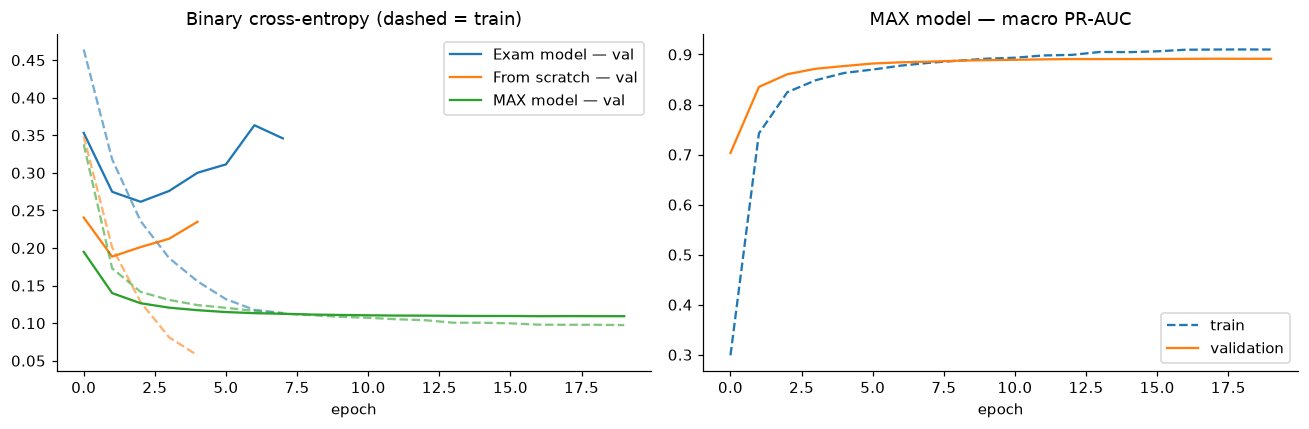

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, name in [(h_exam, "Exam model"), (h_scratch, "From scratch"), (h_max, "MAX model")]:
    l, = ax[0].plot(h.history["val_loss"], label=f"{name} — val")
    ax[0].plot(h.history["loss"], "--", color=l.get_color(), alpha=0.6)
ax[0].set_title("Binary cross-entropy (dashed = train)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h_max.history["pr_auc"], "--", label="train"); ax[1].plot(h_max.history["val_pr_auc"], label="validation")
ax[1].set_title("MAX model — macro PR-AUC"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves.png", bbox_inches="tight"); plt.show()

## 8. Ablation study — what does each input contribute?

Starting from the final model, one input branch is removed or added at a time (same seed, same protocol).

In [11]:
run("MAX − metadata (year, month)", use_emb=True, use_meta=False)
run("MAX + TF-IDF branch", use_emb=True, use_tfidf=True)
run("MAX + TF-IDF + BiGRU branches", use_emb=True, use_tfidf=True, use_seq=True);

MAX − metadata (year, month)             20 epochs,   13s


MAX + TF-IDF branch                       6 epochs,   24s


MAX + TF-IDF + BiGRU branches             5 epochs,  113s


## 9. Results

The decision rule of each model is selected on the **validation** set (macro-F1); the table reports its **test** score.

In [12]:
res = pd.concat(RESULTS, ignore_index=True)
best_rule = (res[res.split == "val"].sort_values("macro-F1", ascending=False)
             .groupby("model", sort=False).head(1)[["model", "rule"]])
summary = (res[res.split == "test"].merge(best_rule, on=["model", "rule"])
           .drop(columns="split").set_index("model").sort_values("macro-F1", ascending=False))
display(summary.round(4))
summary.round(4).to_csv("results.csv")

print("\nEffect of the decision rule (test set, MAX model):")
display(res[(res.model == "MAX model") & (res.split == "test")].drop(columns=["model", "split"]).set_index("rule").round(4))

,rule,micro-F1,macro-F1,sample-F1,Hamming,exact match,PR-AUC
model,,,,,,,
MAX model,tuned,0.8560,0.8271,0.8540,0.0412,0.7267,0.8935
mpnet embeddings + LogReg,hierarchical,0.8551,0.8269,0.8540,0.0409,0.8079,0.8653
MAX + TF-IDF + BiGRU branches,hierarchical,0.8489,0.8185,0.8479,0.0428,0.7979,0.8731
"MAX − metadata (year, month)",tuned,0.8412,0.8132,0.8380,0.0454,0.7018,0.8792
MAX + TF-IDF branch,tuned,0.8384,0.8124,0.8360,0.0465,0.6521,0.8773
TF-IDF + LogReg,hierarchical,0.7911,0.7533,0.7892,0.0590,0.7277,0.7897
From scratch (BiGRU + TF-IDF + meta),tuned,0.7534,0.7031,0.7374,0.0702,0.4769,0.7647
Exam model (BiLSTM),tuned,0.7326,0.6805,0.7182,0.0747,0.5351,0.7310



Effect of the decision rule (test set, MAX model):


,micro-F1,macro-F1,sample-F1,Hamming,exact match,PR-AUC
rule,,,,,,
0.5,0.8547,0.8243,0.8418,0.0402,0.7333,0.8935
tuned,0.8560,0.8271,0.8540,0.0412,0.7267,0.8935
tuned + top-2,0.8555,0.8271,0.8566,0.0416,0.7318,0.8935
hierarchical,0.8562,0.8282,0.8547,0.0406,0.8090,0.8935


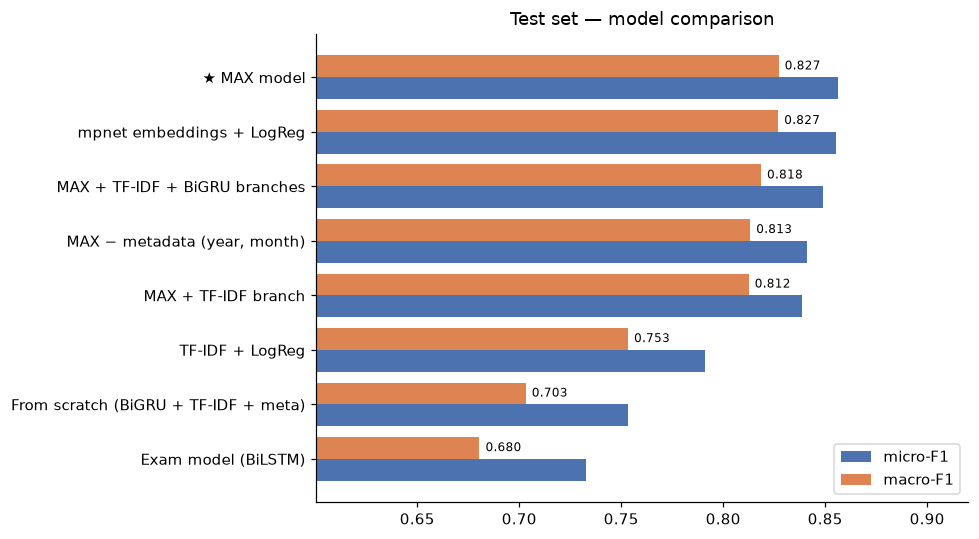

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
order = summary.index[::-1]
y = np.arange(len(order))
ax.barh(y - 0.2, summary.loc[order, "micro-F1"], 0.4, label="micro-F1", color="#4C72B0")
ax.barh(y + 0.2, summary.loc[order, "macro-F1"], 0.4, label="macro-F1", color="#DD8452")
ax.set_yticks(y); ax.set_yticklabels([("★ " if m == "MAX model" else "") + m for m in order])
ax.set_xlim(max(0, summary[["micro-F1", "macro-F1"]].values.min() - 0.08), 0.92)
for yi, m in zip(y, order):
    ax.text(summary.loc[m, "macro-F1"] + 0.003, yi + 0.2, f"{summary.loc[m, 'macro-F1']:.3f}", va="center", fontsize=8)
ax.set_title("Test set — model comparison"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/model_comparison.png", bbox_inches="tight"); plt.show()

## 10. Error analysis of the final model

decision rule: tuned


,precision,recall,F1,support
BUSINESS,0.713,0.720,0.716,300
ENVIRONMENT,0.753,0.710,0.731,300
SCIENCE,0.811,0.687,0.744,300
POLITICS,0.706,0.793,0.747,300
WELLNESS,0.699,0.820,0.755,300
WORLD NEWS,0.840,0.750,0.792,300
TECH,0.827,0.797,0.812,300
ECONOMY & TECH,0.824,0.853,0.839,600
PARENTING,0.844,0.847,0.845,300
ENTERTAINMENT,0.802,0.893,0.845,300


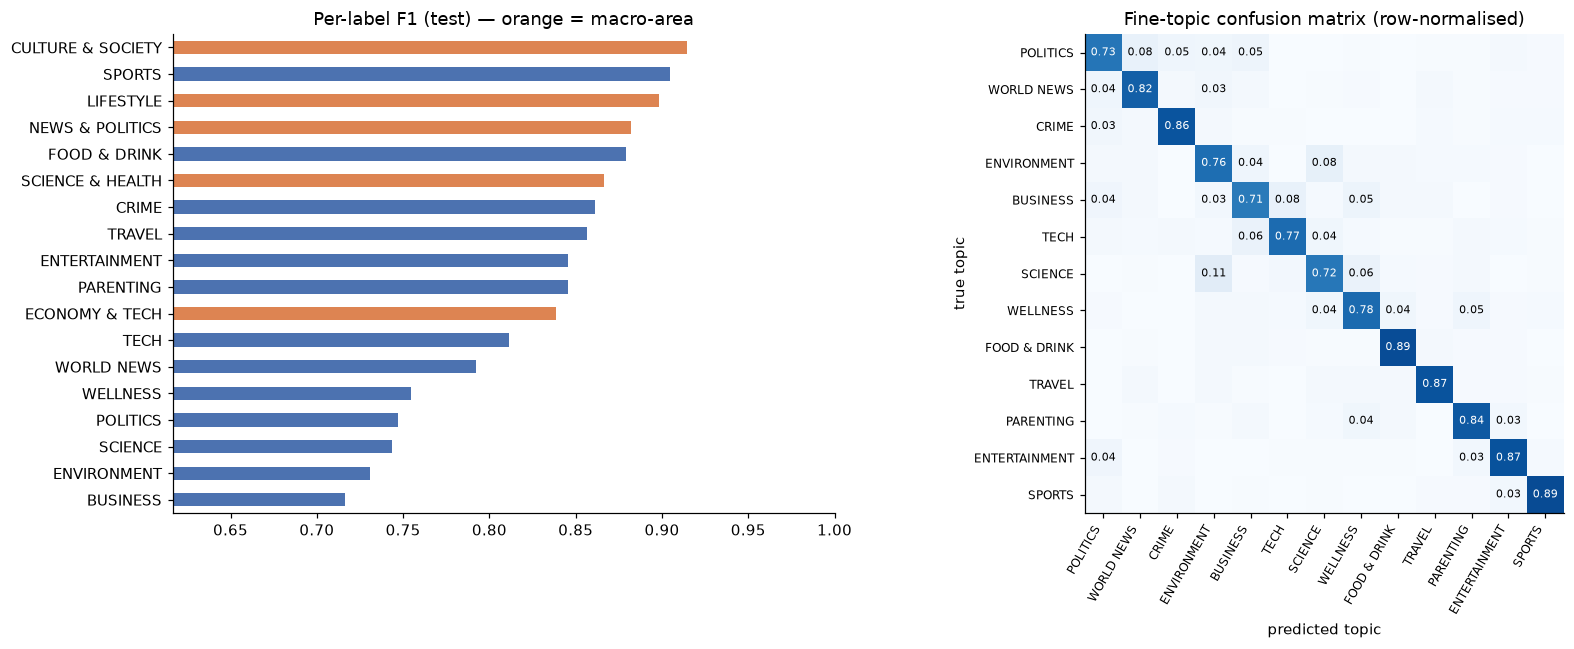

In [14]:
FINAL = "MAX model"
final_rule = best_rule.set_index("model").loc[FINAL, "rule"]
p_va, p_te, th = PROBA[FINAL]
pred = decode(p_te, final_rule, th)
yt = Y_te.astype(int)
per_label = pd.DataFrame({"precision": precision_score(yt, pred, average=None, zero_division=0),
                          "recall": recall_score(yt, pred, average=None, zero_division=0),
                          "F1": f1_score(yt, pred, average=None, zero_division=0),
                          "support": yt.sum(0)}, index=LABELS)
print("decision rule:", final_rule)
display(per_label.round(3).sort_values("F1"))

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.25]})
f1s = per_label["F1"].sort_values()
f1s.plot.barh(ax=ax[0], color=["#DD8452" if l in MACRO else "#4C72B0" for l in f1s.index])
ax[0].set_xlim(f1s.min() - 0.1, 1); ax[0].set_title("Per-label F1 (test) — orange = macro-area")
cm = confusion_matrix(topic[idx_te], p_te[:, :N_FINE].argmax(1), normalize="true")
ax[1].imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax[1].set_xticks(range(N_FINE)); ax[1].set_xticklabels(FINE, rotation=60, ha="right", fontsize=8)
ax[1].set_yticks(range(N_FINE)); ax[1].set_yticklabels(FINE, fontsize=8)
for i in range(N_FINE):
    for j in range(N_FINE):
        if cm[i, j] >= 0.03:
            ax[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
ax[1].set_xlabel("predicted topic"); ax[1].set_ylabel("true topic"); ax[1].set_title("Fine-topic confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/error_analysis.png", bbox_inches="tight"); plt.show()

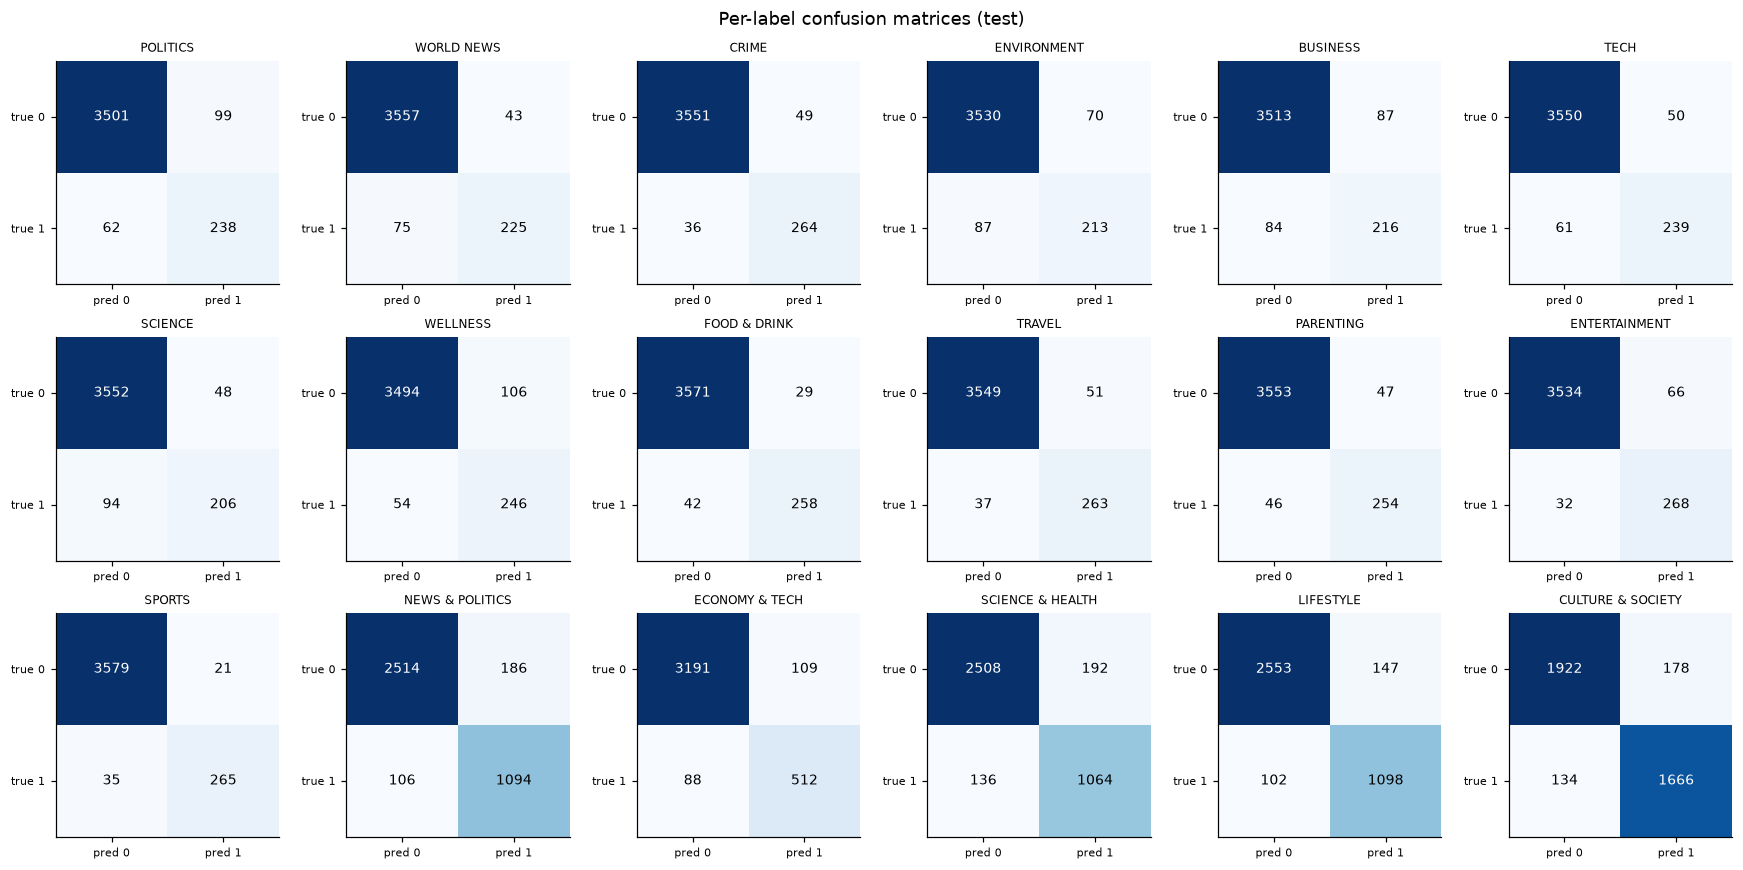

In [15]:
# Per-label 2x2 confusion matrices [[TN, FP], [FN, TP]] (the exam's evaluation, kept for completeness)
mcm = multilabel_confusion_matrix(yt, pred)
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for k, axk in enumerate(axes.ravel()):
    axk.imshow(mcm[k], cmap="Blues")
    for i in range(2):
        for j in range(2):
            axk.text(j, i, mcm[k][i, j], ha="center", va="center", fontsize=9,
                     color="white" if mcm[k][i, j] > mcm[k].max() / 2 else "black")
    axk.set_title(LABELS[k], fontsize=8); axk.set_xticks([0, 1], ["pred 0", "pred 1"], fontsize=7); axk.set_yticks([0, 1], ["true 0", "true 1"], fontsize=7)
plt.suptitle("Per-label confusion matrices (test)"); plt.tight_layout(); plt.show()

In [16]:
# Most confident mistakes: where does the model fail?
true_t, pred_t = topic[idx_te], p_te[:, :N_FINE].argmax(1)
wrong = np.flatnonzero(true_t != pred_t)
wrong = wrong[np.argsort(-p_te[wrong, pred_t[wrong]])][:8]
pd.set_option("display.max_colwidth", 140)
display(pd.DataFrame({"text": X_te["text"][wrong], "year": X_te["year"][wrong],
                      "true": [FINE[i] for i in true_t[wrong]], "predicted": [FINE[i] for i in pred_t[wrong]],
                      "confidence": p_te[wrong, pred_t[wrong]].round(3)}))

,text,year,true,predicted,confidence
0,Watch Hopeful Guy Challenge Ex-NBA Scrub Brian Scalabrine To 1-On-1. This gym encounter had a decisive result.,2021,ENTERTAINMENT,SPORTS,1.000
1,This Is What Inspired Elon Musk To Get Into The Modern Space Race. It all started 15 years ago.,2016,TECH,SCIENCE,0.998
2,"Google, Privacy, and the Age of the Platform. Nowhere is it written that you have to watch videos on YouTube or write emails on Gmail. I...",2012,BUSINESS,TECH,0.997
3,2013 National Geographic Traveler Photo Contest Receives Stunning Entries. Entries for the 25th annual National Geographic Traveler phot...,2013,ENVIRONMENT,TRAVEL,0.995
4,Veteran NFL Star Turns Self In To Face Strip Club Assault Charge.,2015,CRIME,SPORTS,0.993
5,Indonesia restores military ties with Australia after latest neighbourly dispute.,2017,POLITICS,WORLD NEWS,0.993
6,Michael Wright Found Dead And Covered In Trash Bags In Brooklyn. The medical examiner has ruled Wright's death a homicide.,2015,SPORTS,CRIME,0.992
7,"WHO Urges Trump To Expand, Not Repeal, Obamacare. ""This would be a setback if people would lose coverage.""",2016,WELLNESS,POLITICS,0.992


## 11. Robustness — variance across random seeds

A single run can be lucky. The final model is retrained with 5 different seeds (same split).

In [17]:
seed_scores = []
for s in range(1, 6):
    set_seed(s); m = build_model(use_emb=True, name="seed_run"); fit(m, verbose=0)
    pv, pt = m.predict(feed(m, I_va), verbose=0), m.predict(feed(m, I_te), verbose=0)
    seed_scores.append(metrics(Y_te, decode(pt, final_rule, tune_thresholds(Y_va, pv)), pt))
seed_df = pd.DataFrame(seed_scores)
display(seed_df.agg(["mean", "std"]).round(4))

,micro-F1,macro-F1,sample-F1,Hamming,exact match,PR-AUC
mean,0.8553,0.8277,0.8539,0.0415,0.7251,0.8933
std,0.0007,0.0008,0.0014,0.0003,0.0040,0.0006


## 12. Packaging for inference

The trained head is exported as a `.keras` file, with a JSON config holding the encoder name, labels and tuned
thresholds. Tokenisation and the year lookup are layers of the model, so inference needs only raw inputs.

In [18]:
best.save(f"{MODEL_DIR}/news_tagger.keras")
with open(f"{MODEL_DIR}/news_tagger_config.json", "w") as f:
    json.dump({"encoder": ENCODER, "labels": LABELS, "thresholds": th.round(3).tolist(),
               "decision_rule": final_rule, "fine_topics": FINE, "taxonomy": TOPICS}, f, indent=2)

reloaded = keras.models.load_model(f"{MODEL_DIR}/news_tagger.keras")
cfg = json.load(open(f"{MODEL_DIR}/news_tagger_config.json"))

def tag(texts_in, year, month):
    n = len(texts_in)
    I = as_inputs({"text": np.array(texts_in), "year": np.full(n, year), "month": np.full(n, month)})
    I["emb"] = tf.constant(encoder.encode(list(texts_in), normalize_embeddings=True))
    p = reloaded.predict(feed(reloaded, I), verbose=0)
    pred = decode(p, cfg["decision_rule"], np.array(cfg["thresholds"]))
    return [[cfg["labels"][k] for k in np.flatnonzero(row)] for row in pred]

demo = ["Senate passes bipartisan bill to lower prescription drug prices. The measure now heads to the House.",
        "10 hidden beaches in Portugal you need to visit this summer",
        "Apple unveils new chip that promises faster AI on laptops",
        "How to get your toddler to sleep through the night, according to pediatricians",
        "Wildfires force thousands to evacuate as record heat wave grips the West"]
for t, labs in zip(demo, tag(demo, 2021, 6)):
    print(f"{t[:70]:<72} -> {labs}")

Senate passes bipartisan bill to lower prescription drug prices. The m   -> ['POLITICS', 'NEWS & POLITICS']
10 hidden beaches in Portugal you need to visit this summer              -> ['TRAVEL', 'LIFESTYLE', 'CULTURE & SOCIETY']
Apple unveils new chip that promises faster AI on laptops                -> ['TECH', 'ECONOMY & TECH', 'SCIENCE & HEALTH']
How to get your toddler to sleep through the night, according to pedia   -> ['PARENTING', 'LIFESTYLE', 'CULTURE & SOCIETY']
Wildfires force thousands to evacuate as record heat wave grips the We   -> ['ENVIRONMENT', 'NEWS & POLITICS', 'SCIENCE & HEALTH']


## 13. Conclusions

| Step | Test macro-F1 | What we learn |
|---|---|---|
| Exam model (BiLSTM, from scratch) | 0.680 | solid design, limited by data size |
| Improved from-scratch model | 0.703 | pooling, TF-IDF bi-grams, date embeddings, early stopping help (+2.3 pts)… |
| TF-IDF + Logistic Regression | 0.753 | …but a linear n-gram model is still better with ~18k training texts |
| **MAX: pretrained encoder + date embeddings** | **0.827** | **transfer learning is the decisive step (+7.4 pts over the baseline, +14.7 over the exam)** |

- **Metadata matters:** removing year/month costs 1.4 macro-F1 points — HuffPost's editorial mix changes over time.
- **More capacity is not better:** adding TF-IDF or BiGRU branches on top of the pretrained embedding *lowers* the
  score (they overfit within 5–6 epochs). The simplest head on the best representation wins.
- **MAX vs. a linear head on the same embeddings:** same F1, but **+2.8 PR-AUC points** — the neural head ranks
  labels better, which matters for top-k suggestions and human-in-the-loop triage.
- **The decision rule is a product choice:** taxonomy-consistent decoding raises exact-match accuracy from 0.73 to
  0.81 at equal F1 — preferable when the whole label set is consumed downstream.
- **Remaining errors** are between overlapping topics (celebrity stories across Sports / Entertainment / Crime,
  Tech ↔ Science, Business ↔ Tech); several are arguably ambiguous or mislabelled in the source data.

**Limitations.** Macro-areas are derived from the topic taxonomy (the original exam data is not public), so they are
easier than independently annotated labels; results come from one corpus and one time-agnostic split.

**Next steps.** Fine-tune the encoder end-to-end on a GPU, train on the full 200k-article corpus, use a
time-based split to measure drift, calibrate probabilities, and serve `tag()` behind a small REST API.
